### how can a model find those parameters automatically when the data is large and noisy? 
### That's where the cost function and gradient descent come in.

Cost function: measuring model error
A cost function measures how poorly a model's predictions match the actual targets.

We'll use Mean Squared Error (MSE):

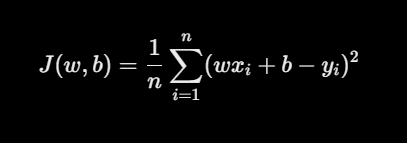

Here, \(n\) is the number of observations.
- A smaller MSE means smaller squared prediction errors.
- An MSE of zero means all predictions match the targets exactly.
- Large errors receive a larger penalty because the errors are squared.

### Calculate MSE manually

In [2]:
import numpy as np

X = np.array([1, 2, 3], dtype=float)
y = np.array([3, 5, 7], dtype=float)

def mse_cost(X, y, w, b):
    predictions = w * X + b
    return np.mean((predictions - y) ** 2)

print("Cost with w=2, b=1:", mse_cost(X, y, w=2, b=1))
print("Cost with w=1, b=0:", mse_cost(X, y, w=1, b=0))

Cost with w=2, b=1: 0.0
Cost with w=1, b=0: 9.666666666666666


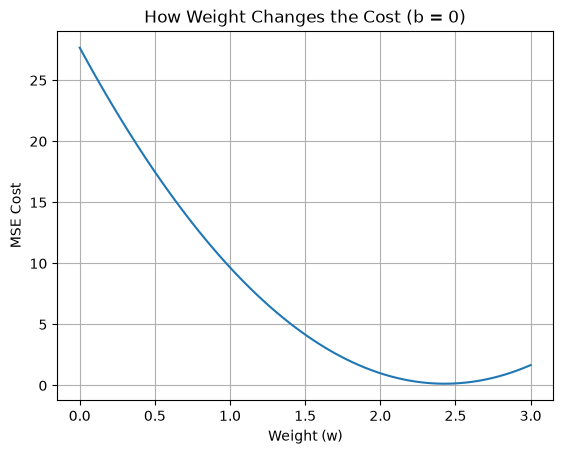

In [3]:
import matplotlib.pyplot as plt

weights = np.linspace(0, 3, 100)
costs = [mse_cost(X, y, w, b=0) for w in weights]

plt.plot(weights, costs)
plt.xlabel("Weight (w)")
plt.ylabel("MSE Cost")
plt.title("How Weight Changes the Cost (b = 0)")
plt.grid(True)
plt.show()

### Gradient descent: learning by updating parameters
Gradient descent is an optimization algorithm. It repeatedly adjusts model parameters in the direction that reduces the cost.

The update rules for linear regression using MSE are:

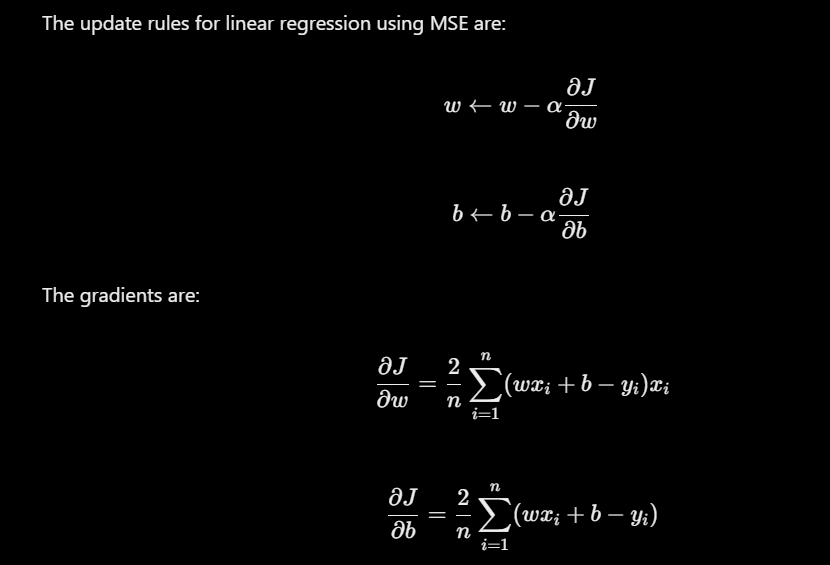

Here, \(\alpha\) is the learning rate — the size of each parameter update

### Implement gradient descent from scratch
This is the most important practical exercise in this lesson.

In [4]:
import numpy as np

X = np.array([1, 2, 3], dtype=float)
y = np.array([3, 5, 7], dtype=float)

w = 0.0
b = 0.0

learning_rate = 0.05
epochs = 1000
n = len(X)

cost_history = []

for epoch in range(epochs):
    predictions = w * X + b
    errors = predictions - y

    dw = (2 / n) * np.sum(errors * X)
    db = (2 / n) * np.sum(errors)

    w = w - learning_rate * dw
    b = b - learning_rate * db

    cost_history.append(mse_cost(X, y, w, b))

print("Learned weight:", w)
print("Learned bias:", b)
print("Final MSE:", cost_history[-1])

Learned weight: 2.0000002481557733
Learned bias: 0.9999994358835982
Final MSE: 4.5651690239631676e-14


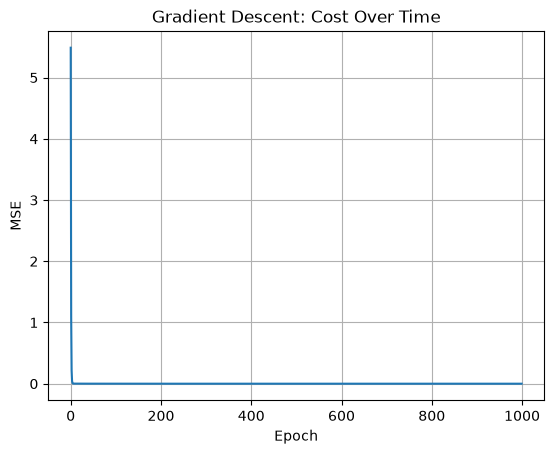

In [5]:
import matplotlib.pyplot as plt

plt.plot(cost_history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent: Cost Over Time")
plt.grid(True)
plt.show()